Olá, Andeza 

Meu nome é Ramon. Ao ao longo do texto farei algumas observações sobre melhorias no código. Nas partes em que não houver comentários, está tudo certo, ok? Estarei aberto a feedbacks e discussões sobre o tema.

**Peço que mantenha e não altere os comentários que eu fizer por aqui para que possamos nos localizar posteriormente, ok?**

Mais uma coisa, vamos utilizar um código de cores para você entender os meus feedbacks no seu notebook. Funciona assim:

<div class="alert alert-block alert-success">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Alerta não crítco, mas que pode ser corrigido para melhoria geral no seu código/análise
</div>

<div class="alert alert-block alert-danger">

<b>Comentário do revisor: </b> <a class="tocSkip"></a>
    
Erro que precisa ser consertado, caso contrário seu projeto **não** será aceito.
</div>

Você pode me responder usando isso:
<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div>

###

<div class="alert alert-block alert-success">
<b>Comentário Geral do Revisor</b> <a class="tocSkip"></a>

Obrigado por enviar seu projeto. 
    
Parabéns, você fez um bom trabalho.

Como pontos fortes do projeto, destaco:
- Código simples e eficiente (sem loop desnecessário)
- Uso adequado dos recursos da lição
- boa lógica de programação
- definiu as hipóteses do teste de hipótese; usou teste Levene para avaliar variâncias


<span class="text-danger">Porém, há espaço para melhorias conforme os itens apontados anteriormente. Destaco os  pontos a seguir: </span>
 * <span class="text-danger"> ajustar teste de hipótese </span>


Portanto, sugiro que você corrija os pontos indicados.
    
Se você tiver alguma dúvida sobre de algo que você não tenha entendido, sinta-se à vontade para perguntar ao tutor ou deixar um comentário em **azul** para que, na próxima iteração, eu possa responder.

Conte conosco. Lembre-se de que você pode tirar dúvidas com revisores usando os comentários ou buscar ajuda de um tutor.
Bom trabalho. 


</div>



<div class="alert alert-block alert-success">
<b> Comentário Geral do revisor: </b> <a class="tocSkip"></a>

Tudo certo agora. Parabéns pelo empenho. Desejo sucesso na jornada.

</div>


# Qual é o melhor plano?

Você trabalha como analista para a empresa de telecomunicações Megaline. A empresa oferece aos clientes dois planos pré-pagos: Surf e Ultimate. O departamento comercial quer saber qual dos planos gera mais receita para ajustar o orçamento de publicidade.

Você vai realizar uma análise preliminar dos planos com base em uma pequena seleção de clientes. Você terá dados de 500 clientes da Megaline: que clientes são, de onde eles são, qual plano usam e o número de chamadas e mensagens realizadas em 2018. Seu trabalho é analisar o comportamento dos clientes e determinar qual plano pré-pago gera mais receita.

[Fornecemos alguns comentários para guiar sua linha de raciocínio enquanto você trabalha neste projeto. Entretanto, certifique-se de remover todos os comentários entre colchetes antes de enviar o projeto.]

[Antes de começar a análise dos dados, explique com suas próprias palavras o propósito do projeto e as ações que planeja realizar.]

[Tenha em mente que estudar, modificar e analisar dados é um processo iterativo. É normal retornar a etapas anteriores e corrigir/expandir algo para permitir as próximas etapas.]

## Inicialização

In [1]:
# Carregando todas as bibliotecas
import pandas as pd
import numpy as np
from scipy import stats as st
import math
import matplotlib.pyplot as plt


## Carregue os dados

In [2]:
# Carregue os arquivos de dados em diferentes DataFrames
df_calls = pd.read_csv('/datasets/megaline_calls.csv')
df_internet = pd.read_csv('/datasets/megaline_internet.csv')
df_messages = pd.read_csv('/datasets/megaline_messages.csv')
df_plans = pd.read_csv('/datasets/megaline_plans.csv')
df_users = pd.read_csv('/datasets/megaline_users.csv')

## Prepare os dados

[Os dados deste projeto estão divididos em várias tabelas. Explore cada uma para obter uma compreensão inicial dos dados. Faça correções em cada tabela, se necessário.]

## Planos

In [3]:
# Imprima informações gerais/resumo sobre o DataFrame dos planos
df_plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


In [4]:
# Imprima uma amostra de dados dos planos
print(df_plans)

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

O dataframe possui apenas duas linhas, que correspondem aos planos surf e ultimate, as colunas tem o os tipos de dados corretos.
A coluna MB_per_mouth_included aparece em MB, mas no enunciado a franquia foi dada em GB, ex 15 GB - 15360 MB isso já está correto, mas para ter melhor clareza é melhor transformar tudo em GB, porém o arredondamento mencionado no enunciado ( minutos - sempre arredonadar pra cima) não está representado no dataframe.

## Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

As correções que vou fazer são:
padronizar a unidade de dados para mais clareza de MB para GB - coluna mb_per_mouth_included para gb_per_mouth_included
as colunas usd_per_message e usd_per_minute trasformar em número inteiro para ter mais precisão.
os códigos estarão na célula abaixo.

## Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

Observação: a Megaline arredonda segundos para minutos e megabytes para gigabytes. Para chamadas, cada chamada individual é arredondada para cima: mesmo que uma chamada tenha durado apenas um segundo, um minuto será contado. Para tráfego da web, sessões individuais da web não são arredondadas para cima. Ao invés disso, o total do mês é arredondado para cima. Se alguém usar 1.025 megabytes no mês, a cobrança será de 2 gigabytes.

Não inclui nada, acredito que as correções feitas anteriormente já suprem o que é necessário para as analises.

In [5]:
import pandas as pd
planos = pd.DataFrame([  # ← CORRETO: 'DataFrame' com 'F' maiúsculo
    {"plan_name" : "surf",
     "usd_mountly_pay": 20,
     "minutes_included":500,
     "message_included":50,
     "mb_per_mouth_included":15360, #15 GB em MB
     "gb_per_mouth_included":15,
     "usd_per_minute":0.03,
     "usd_per_minute_cents":3,
     "usd_per_message":0.03,
     "usd_per_message_cents":3,
     "usd_per_gb":10,
    },
    {"plan_name" : "ultimate",
     "usd_mountly_pay":70,
     "minutes_included":3000,
     "message_included":1000,
     "mb_per_mouth_included":30720, #30 GB em MB
     "gb_per_mouth_included":30,
     "usd_per_minute":0.01,
     "usd_per_minute_cents":1,
     "usd_per_message":0.01,
     "usd_per_message_cents":1,
     "usd_per_gb":7,
    }
])
print(planos)

  plan_name  usd_mountly_pay  minutes_included  message_included  \
0      surf               20               500                50   
1  ultimate               70              3000              1000   

   mb_per_mouth_included  gb_per_mouth_included  usd_per_minute  \
0                  15360                     15            0.03   
1                  30720                     30            0.01   

   usd_per_minute_cents  usd_per_message  usd_per_message_cents  usd_per_gb  
0                     3             0.03                      3          10  
1                     1             0.01                      1           7  



<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div> Ramon, eu refiz o código aqui abaixo, veja se agora está correto, eu ainda não deletei o que fiz acima para que possa comparar, mas assim que retornar eu apa


In [6]:
# df_plans com métricas adicionais de minutos e mensagens em centavos para facilitar a análise
df_plans['usd_per_minute_cents'] = df_plans['usd_per_minute'] * 100
df_plans['usd_per_message_cents'] = df_plans['usd_per_message'] * 100

#criar a coluna GB (convertendo de MB)
df_plans['gb_per_month_included'] = df_plans['mb_per_month_included'] / 1024

# Visualizar resultado
print(df_plans)

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  \
0               20          10             0.03            0.03      surf   
1               70           7             0.01            0.01  ultimate   

   usd_per_minute_cents  usd_per_message_cents  gb_per_month_included  
0                   3.0                    3.0                   15.0  
1                   1.0                    1.0                   30.0  




<div class="alert alert-block alert-danger">
<b> Comentário do revisor v1: </b> <a class="tocSkip"></a>

- código harcoded não é adequado
- precisa usar dados froencidos no dataframe plans.csv

</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

Está correto, pois você está usando df_plans ao fazer o merge
</div>


## Usuários

In [7]:
# Imprima informações gerais/resumo sobre o DataFrame dos usuários
df_users.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [8]:
# Imprima uma amostra de dados dos usuários
print(df_users)

     user_id first_name   last_name  age  \
0       1000   Anamaria       Bauer   45   
1       1001     Mickey   Wilkerson   28   
2       1002     Carlee     Hoffman   36   
3       1003   Reynaldo     Jenkins   52   
4       1004    Leonila    Thompson   40   
..       ...        ...         ...  ...   
495     1495      Fidel      Sharpe   67   
496     1496      Ariel    Shepherd   49   
497     1497      Donte     Barrera   49   
498     1498       Scot  Williamson   51   
499     1499      Shena     Dickson   37   

                                          city    reg_date      plan  \
0        Atlanta-Sandy Springs-Roswell, GA MSA  2018-12-24  ultimate   
1              Seattle-Tacoma-Bellevue, WA MSA  2018-08-13      surf   
2         Las Vegas-Henderson-Paradise, NV MSA  2018-10-21      surf   
3                                Tulsa, OK MSA  2018-01-28      surf   
4              Seattle-Tacoma-Bellevue, WA MSA  2018-05-23      surf   
..                                     

In [9]:
df_users['plan'].value_counts()

surf        339
ultimate    161
Name: plan, dtype: int64

[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

Verifiquei que as colunas reg_date e churn_date estão como object mas deveriam ser datetime, plan e city também estao como object mas poderiam ser category para facilitar as analises.
na coluna churn_date temos valores ausentes, o que pode significar que a maioria dos clientes ainda está ativa.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [10]:
import pandas as pd
#convertendo para datetime
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'])
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'])

#convertendo colunas para category
df_users['plan'] = df_users['plan'].astype('category')
df_users['city'] = df_users['city'].astype('category')

#print(df_users)
df_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    category      
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    category      
 7   churn_date  34 non-null     datetime64[ns]
dtypes: category(2), datetime64[ns](2), int64(2), object(2)
memory usage: 27.3+ KB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

Vou criar uma coluna is_active para saber os clientes que estão ativos e facilitar para possíveis filtros
criar coluna com tempo de permanência para clientes ativos e inativos
coluna plan_type como categoria e coluna city_state separando cidade de estados para possíveis análises geográficos ( usando  o split)

In [11]:
from datetime import datetime

#criar coluna booleana pora indicar se o cliente está ativo
df_users['is_active'] = df_users['churn_date'].isna()

#calcular tempo de permanencia em dias e meses
df_users['days_with_company'] = (df_users['churn_date'].fillna(pd.Timestamp.today()) - df_users['reg_date']).dt.days
df_users['months_with_company'] = (df_users['days_with_company'] / 30).astype(int)

#extraindo o nome da cidade (antes da vírgula)
df_users['city_name'] = df_users['city'].str.split(',').str[0]
#extraindo apenas a sigla do estado(depois da vírgula, 2 caracteres)
df_users['state'] = df_users['city'].str.split(',').str[1].str.strip().str[:2]

print(df_users)

     user_id first_name   last_name  age  \
0       1000   Anamaria       Bauer   45   
1       1001     Mickey   Wilkerson   28   
2       1002     Carlee     Hoffman   36   
3       1003   Reynaldo     Jenkins   52   
4       1004    Leonila    Thompson   40   
..       ...        ...         ...  ...   
495     1495      Fidel      Sharpe   67   
496     1496      Ariel    Shepherd   49   
497     1497      Donte     Barrera   49   
498     1498       Scot  Williamson   51   
499     1499      Shena     Dickson   37   

                                          city   reg_date      plan  \
0        Atlanta-Sandy Springs-Roswell, GA MSA 2018-12-24  ultimate   
1              Seattle-Tacoma-Bellevue, WA MSA 2018-08-13      surf   
2         Las Vegas-Henderson-Paradise, NV MSA 2018-10-21      surf   
3                                Tulsa, OK MSA 2018-01-28      surf   
4              Seattle-Tacoma-Bellevue, WA MSA 2018-05-23      surf   
..                                         ..

## Chamadas

In [12]:
# Imprima informações gerais/resumo sobre o DataFrame das chamadas
df_calls.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


In [13]:
# Imprima uma amostra de dados das chamadas
print(df_calls.head(10))


         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22
5  1000_388     1000  2018-12-31      2.20
6  1000_510     1000  2018-12-27      5.75
7  1000_521     1000  2018-12-28     14.18
8  1000_530     1000  2018-12-28      5.77
9  1000_544     1000  2018-12-26      4.40


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

A Coluna call_date está como object mas deveria ser datetime para permitir as análises com datas, a coluna ID poderia estar separada depois do snakecase para poder também ajudar nas análises e filtros, não há dados NAN.
vou incluir duas colunas, uma para mês e outra para ano para ajudar nas análises de data, como no DF de planos vou arredondar a coluna de Duration poara atender as regras de cobrança e uma coluna de dia da semana para ver padrõe de uso.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [14]:
import pandas as pd

#converter call_data para datetime

df_calls['call_date'] = pd.to_datetime(df_calls['call_date'])

df_calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [15]:
#duração arredondada para cobrança ( arred para cima)

import numpy as np

df_calls['arred_duration'] = np.ceil(df_calls['duration'])

#mês e ano das chamadas
df_calls['month'] = df_calls['call_date'].dt.month
df_calls['year'] = df_calls['call_date'].dt.year

#dia da semana (domingo = 6)
df_calls['day_of_week'] = df_calls['call_date'].dt.dayofweek

print(df_calls)



              id  user_id  call_date  duration  arred_duration  month  year  \
0        1000_93     1000 2018-12-27      8.52             9.0     12  2018   
1       1000_145     1000 2018-12-27     13.66            14.0     12  2018   
2       1000_247     1000 2018-12-27     14.48            15.0     12  2018   
3       1000_309     1000 2018-12-28      5.76             6.0     12  2018   
4       1000_380     1000 2018-12-30      4.22             5.0     12  2018   
...          ...      ...        ...       ...             ...    ...   ...   
137730  1499_199     1499 2018-11-21      8.72             9.0     11  2018   
137731  1499_200     1499 2018-10-20     10.89            11.0     10  2018   
137732  1499_201     1499 2018-09-21      8.12             9.0      9  2018   
137733  1499_202     1499 2018-10-10      0.37             1.0     10  2018   
137734  1499_203     1499 2018-12-29     13.86            14.0     12  2018   

        day_of_week  
0                 3  
1      

## Mensagens

In [16]:
# Imprima informações gerais/resumo sobre o DataFrame das mensagens
df_messages.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [17]:
# Imprima uma amostra dos dados das mensagens
print(df_messages.head(10))


         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26
5  1000_346     1000   2018-12-29
6  1000_386     1000   2018-12-30
7  1000_413     1000   2018-12-31
8  1000_502     1000   2018-12-27
9  1000_525     1000   2018-12-28


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

Não há valores nulos, a coluna message_date está como object mas deveria ser datetime, user ID está correto como número inteiro.
Vou criar como nos outros uma coluna ano, mes e dia da semana para ajudar nas análises, e uma coluna quantidade de mensagens por usuarios no mês.

### Corrija os dados

In [18]:

import pandas as pd

#converter para datetime
df_messages['message_date']= pd.to_datetime(df_messages['message_date'],errors = 'coerce')


df_messages.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [19]:

#mês.ano e dia da semana das chamadas
df_messages['month'] = df_messages['message_date'].dt.month
df_messages['year'] = df_messages['message_date'].dt.year
df_messages['day_of_week'] = df_messages['message_date'].dt.dayofweek

print(df_messages)


             id  user_id message_date  month  year  day_of_week
0      1000_125     1000   2018-12-27     12  2018            3
1      1000_160     1000   2018-12-31     12  2018            0
2      1000_223     1000   2018-12-31     12  2018            0
3      1000_251     1000   2018-12-27     12  2018            3
4      1000_255     1000   2018-12-26     12  2018            2
...         ...      ...          ...    ...   ...          ...
76046  1497_526     1497   2018-12-24     12  2018            0
76047  1497_536     1497   2018-12-24     12  2018            0
76048  1497_547     1497   2018-12-31     12  2018            0
76049  1497_558     1497   2018-12-24     12  2018            0
76050  1497_613     1497   2018-12-23     12  2018            6

[76051 rows x 6 columns]


## Internet

In [20]:
# Imprima informações gerais/resumo sobre o DataFrame da internet
df_internet.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [21]:
#  Imprima uma amostra de dados para o tráfego da internet
print(df_internet.head(10))


         id  user_id session_date  mb_used
0   1000_13     1000   2018-12-29    89.86
1  1000_204     1000   2018-12-31     0.00
2  1000_379     1000   2018-12-28   660.40
3  1000_413     1000   2018-12-26   270.99
4  1000_442     1000   2018-12-27   880.22
5    1001_0     1001   2018-08-24   284.68
6    1001_3     1001   2018-12-09   656.04
7    1001_4     1001   2018-11-04    16.97
8   1001_10     1001   2018-11-27   135.18
9   1001_15     1001   2018-12-13   761.92


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

Seguindo a mesma lógica dos outros dataframes vou transformar a coluna session_date em datetime e criar as colunas de ano, mes e dia da semana, não há valores nulos, vou converter mb_used para GB para facilitar comparação com as franquias de dados e crair coluna com o arredondamento para exemplificar as regras.

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [22]:
import pandas as pd

#converter para datetime
df_internet['session_date'] = pd.to_datetime(df_internet['session_date'],errors = 'coerce')

df_internet.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [23]:
#mês.ano e dia da semana das chamadas
df_internet['month'] = df_internet['session_date'].dt.month
df_internet['year'] = df_internet['session_date'].dt.year
df_internet['day_of_week'] = df_internet['session_date'].dt.dayofweek

#converter mb para gb

df_internet['gb_used'] = df_internet['mb_used'] / 1024

#gb arredondado para cobrança

import numpy as np

df_internet['gb_used_ceil'] = np.ceil(df_internet['gb_used']).astype(int)

print(df_internet)


              id  user_id session_date  mb_used  month  year  day_of_week  \
0        1000_13     1000   2018-12-29    89.86     12  2018            5   
1       1000_204     1000   2018-12-31     0.00     12  2018            0   
2       1000_379     1000   2018-12-28   660.40     12  2018            4   
3       1000_413     1000   2018-12-26   270.99     12  2018            2   
4       1000_442     1000   2018-12-27   880.22     12  2018            3   
...          ...      ...          ...      ...    ...   ...          ...   
104820  1499_215     1499   2018-10-20   218.06     10  2018            5   
104821  1499_216     1499   2018-12-30   304.72     12  2018            6   
104822  1499_217     1499   2018-09-22   292.75      9  2018            5   
104823  1499_218     1499   2018-12-07     0.00     12  2018            4   
104824  1499_219     1499   2018-12-24   758.31     12  2018            0   

         gb_used  gb_used_ceil  
0       0.087754             1  
1       0

## Estude as condições dos planos

[É fundamental entender como os planos funcionam, ou seja, como as cobranças dos usuários são feitas com base na assinatura. Sugerimos imprimir as informações sobre os planos para visualizar novamente as condições.]

In [24]:
# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você
print(planos)


  plan_name  usd_mountly_pay  minutes_included  message_included  \
0      surf               20               500                50   
1  ultimate               70              3000              1000   

   mb_per_mouth_included  gb_per_mouth_included  usd_per_minute  \
0                  15360                     15            0.03   
1                  30720                     30            0.01   

   usd_per_minute_cents  usd_per_message  usd_per_message_cents  usd_per_gb  
0                     3             0.03                      3          10  
1                     1             0.01                      1           7  


## Agregue os dados por usuário

[Agora, como os dados estão limpos, os agregue por usuário e por período para ter apenas um registro dessas informações. Isso vai facilitar muito as próximas análises.]

In [25]:
    # Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.
#print(df_calls)
calls_per_user_month = (
    df_calls
    .groupby(['user_id','month']).size() #contas quantas chamadas cada usuário fez em cada mês
    .reset_index(name = 'num_calls') # coloca o índice com base no agrupamento com a coluna num_calls
)

print(calls_per_user_month)

      user_id  month  num_calls
0        1000     12         16
1        1001      8         27
2        1001      9         49
3        1001     10         65
4        1001     11         64
...       ...    ...        ...
2253     1498     12         39
2254     1499      9         41
2255     1499     10         53
2256     1499     11         45
2257     1499     12         65

[2258 rows x 3 columns]


In [26]:
# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.
minutes_per_user_month = (
    df_calls
    .groupby(['user_id','month'])['arred_duration'].sum() #soma quantas chamadas cada usuário fez em cada mês
    .reset_index(name = 'total_minutes') # coloca o índice com base no agrupamento com a coluna total_minutes
        )

print(minutes_per_user_month)


      user_id  month  total_minutes
0        1000     12          124.0
1        1001      8          182.0
2        1001      9          315.0
3        1001     10          393.0
4        1001     11          426.0
...       ...    ...            ...
2253     1498     12          339.0
2254     1499      9          346.0
2255     1499     10          385.0
2256     1499     11          308.0
2257     1499     12          496.0

[2258 rows x 3 columns]


In [27]:
# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.

messages_per_user_month = (
    df_messages
    .groupby(['user_id','month']).size() #conta quantas chamadas cada usuário fez em cada mês
    .reset_index(name = 'num_messages') # coloca o índice com base no agrupamento com a coluna num_messages
        )

print(messages_per_user_month)



      user_id  month  num_messages
0        1000     12            11
1        1001      8            30
2        1001      9            44
3        1001     10            53
4        1001     11            36
...       ...    ...           ...
1801     1496      9            21
1802     1496     10            18
1803     1496     11            13
1804     1496     12            11
1805     1497     12            50

[1806 rows x 3 columns]


In [28]:
# Calcule o volume de tráfego de internet usado por cada usuário por mês. Salve o resultado.
#print(df_internet)

internet_per_user_month = (
    df_internet
    .groupby(['user_id','month'])['gb_used'].sum() #soma o uso mensal de cada usuário
    .reset_index(name = 'total_gb') # coloca o índice com base no agrupamento com a coluna total_gb
        )

print(internet_per_user_month)



      user_id  month   total_gb
0        1000     12   1.856904
1        1001      8   6.756982
2        1001      9  13.002754
3        1001     10  21.807119
4        1001     11  18.070605
...       ...    ...        ...
2272     1498     12  22.595400
2273     1499      9  12.680430
2274     1499     10  19.035576
2275     1499     11  16.419756
2276     1499     12  21.542197

[2277 rows x 3 columns]


[Coloque os dados agregados em um DataFrame para que cada registro nele represente o que cada usuário consumiu em um determinado mês.]

In [29]:
# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month
df_merged = pd.merge(
    calls_per_user_month,
    minutes_per_user_month,
       on=['user_id','month'],
    how='outer')

df_merged = pd.merge(
    df_merged,
    messages_per_user_month,
       on=['user_id','month'],
    how='outer')

df_merged = pd.merge(
    df_merged,
    internet_per_user_month,
       on=['user_id','month'],
    how='outer')

df_merged = df_merged.fillna(0) 

print(df_merged.head(10))

   user_id  month  num_calls  total_minutes  num_messages   total_gb
0     1000     12       16.0          124.0          11.0   1.856904
1     1001      8       27.0          182.0          30.0   6.756982
2     1001      9       49.0          315.0          44.0  13.002754
3     1001     10       65.0          393.0          53.0  21.807119
4     1001     11       64.0          426.0          36.0  18.070605
5     1001     12       56.0          412.0          44.0  18.915215
6     1002     10       11.0           59.0          15.0   6.398447
7     1002     11       55.0          386.0          32.0  18.891680
8     1002     12       47.0          384.0          41.0  14.058828
9     1003     12      149.0         1104.0          50.0  26.410293


In [30]:
# Adicione as informações sobre o plano
#primeiro vou trazer o nome do plano da tabela users

df_usage_with_plan = pd.merge(
    df_merged,
    df_users[['user_id','plan']],
    on = ['user_id'], 
    how = 'left'
)

#print(df_usage_with_plan)

#agora vou trazer os preços e as franquias da tabela plans
df_usage_with_plan = pd.merge(
    df_usage_with_plan,
    df_plans,
    left_on = 'plan',
    right_on = 'plan_name',
    how = 'left'
)
#removi a coluna plan_name pois estava duplicando a informação
df_usage_with_plan = df_usage_with_plan.drop(columns=['plan_name'])

print(df_usage_with_plan)


      user_id  month  num_calls  total_minutes  num_messages   total_gb  \
0        1000     12       16.0          124.0          11.0   1.856904   
1        1001      8       27.0          182.0          30.0   6.756982   
2        1001      9       49.0          315.0          44.0  13.002754   
3        1001     10       65.0          393.0          53.0  21.807119   
4        1001     11       64.0          426.0          36.0  18.070605   
...       ...    ...        ...            ...           ...        ...   
2288     1349     12        0.0            0.0          61.0  12.734287   
2289     1361      5        0.0            0.0           2.0   1.484072   
2290     1482     10        0.0            0.0           2.0   0.000000   
2291     1108     12        0.0            0.0           0.0   0.227705   
2292     1311      6        0.0            0.0           0.0   1.463701   

          plan  messages_included  mb_per_month_included  minutes_included  \
0     ultimate       

[Calcule a receita mensal para cada usuário: subtraia o limite gratuito do pacote do número total de chamadas, mensagens de texto e dados; multiplique o resultado pelo valor do plano; adicione o preço mensal dependendo do plano. Importante: isso talvez não seja tão simples e necessite de várias linhas, considerando as condições do plano. Portanto, não se preocupe se você passar algum tempo nesta etapa.]

In [31]:
# Calcule a receita mensal para cada usuário
import numpy as np
#excedente de minutos, mensagens e dados
df_revenue = df_usage_with_plan.copy()

#Primeiro vou tirar o limite gratuito do pacote do número otal de chamadas, mensagens e dados
df_revenue['extra minutes'] = np.maximum(df_revenue['total_minutes']-df_revenue['minutes_included'],0)
df_revenue['extra messages'] = np.maximum(df_revenue['num_messages']-df_revenue['messages_included'],0)
df_revenue['extra gb'] = np.maximum(np.ceil(df_revenue['total_gb']) - (df_revenue['mb_per_month_included'] / 1024),0)
                         
#Depois, multiplico o resultado pelo valor do plano e faço a soma do preço mensal.
df_revenue['monthly_revenue'] =(
    df_revenue['usd_monthly_pay'] + 
    df_revenue['extra minutes'] * df_revenue['usd_per_minute']+
    df_revenue['extra messages'] * df_revenue['usd_per_message']+
    df_revenue['extra gb'] * df_revenue['usd_per_gb']
)

print(df_revenue[['user_id', 'month', 'plan', 'monthly_revenue']].head(10))

   user_id  month      plan  monthly_revenue
0     1000     12  ultimate            70.00
1     1001      8      surf            20.00
2     1001      9      surf            20.00
3     1001     10      surf            90.09
4     1001     11      surf            60.00
5     1001     12      surf            60.00
6     1002     10      surf            20.00
7     1002     11      surf            60.00
8     1002     12      surf            20.00
9     1003     12      surf           158.12


## Estude o comportamento do usuário

[Calcule algumas estatísticas descritivas úteis para os dados agregados, o que costuma revelar uma imagem geral capturada pelos dados. Desenhe gráficos úteis para ajudar na compreensão. Já que a tarefa principal é comparar os planos e decidir qual é mais rentável, as estatísticas e os gráficos devem ser calculados por plano.]

[Existem dicas relevantes nos comentários para as chamadas. Essas dicas não foram fornecidas para as mensagens e internet, mas o princípio do estudo estatístico é o mesmo em todos os casos.]

### Chamadas

        plan  month  total_minutes
0       surf      1     203.000000
1       surf      2     297.000000
2       surf      3     330.000000
3       surf      4     351.540000
4       surf      5     399.584416
5       surf      6     431.298969
6       surf      7     449.983471
7       surf      8     410.111111
8       surf      9     414.226804
9       surf     10     429.729958
10      surf     11     423.325088
11      surf     12     473.836478
12  ultimate      1     193.500000
13  ultimate      2     403.142857
14  ultimate      3     304.250000
15  ultimate      4     336.857143
16  ultimate      5     406.241379
17  ultimate      6     370.957447
18  ultimate      7     427.067797
19  ultimate      8     421.436620
20  ultimate      9     437.511628
21  ultimate     10     450.735849
22  ultimate     11     445.196850
23  ultimate     12     459.099338


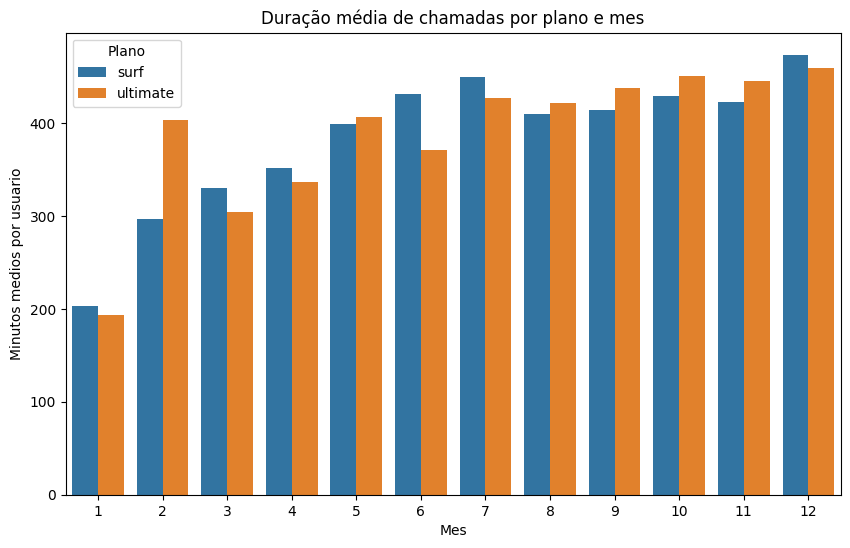

In [32]:
# Compare a duração média das chamadas de cada plano para cada mês. Crie um gráfico de barras para visualizar o resultado.
duration_mean = df_revenue.groupby(['plan', 'month'])['total_minutes'].mean().reset_index()
print(duration_mean)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.barplot(
    data = duration_mean,
    x = 'month',
    y = 'total_minutes',
    hue = 'plan'
)
    
plt.title('Duração média de chamadas por plano e mes')
plt.xlabel('Mes'),
plt.ylabel('Minutos medios por usuario'),
plt.legend(title = 'Plano')
    #plt.xticks(rotation = 45)
plt.show()



Ambos os planos mostram crescimento na duração média de chamada ao longo do meses, no surf o aumento é mais constante e no ultimate há variações entre os meses.
A proximidade entre os valores pode significar uma franquia de minutos semelhantes entre os planos e as diferenças pontuais podem estar ligadas a períodos sazonais, promoções ou perfil regional.

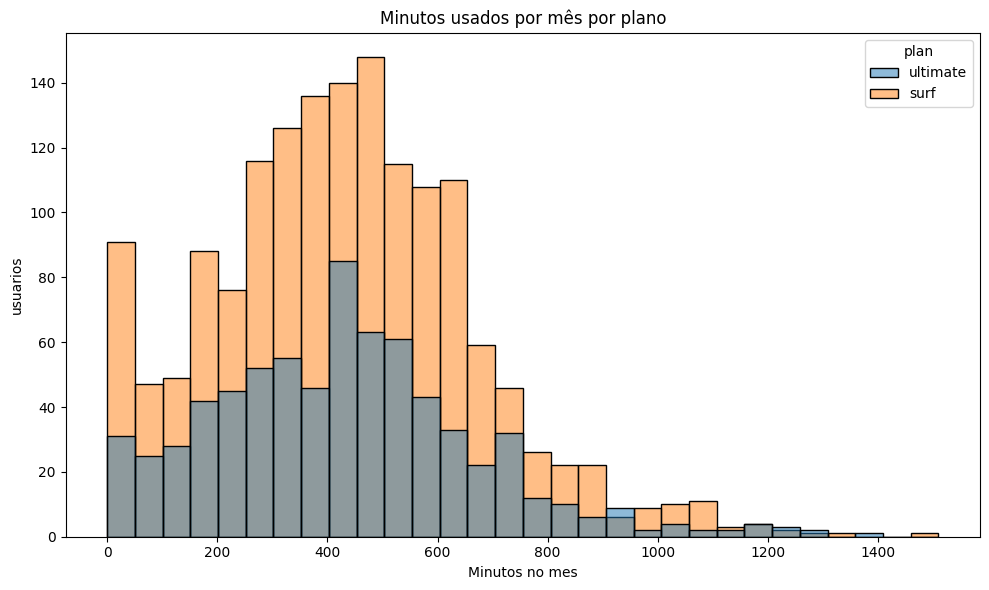

In [33]:
# Compare o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.histplot(
    data = df_revenue,
    x = 'total_minutes',
    hue = 'plan',
    multiple = 'layer', #barras lado a lado
    bins = 30,
    edgecolor = 'black'
)


plt.title('Minutos usados por mês por plano')
plt.xlabel('Minutos no mes'),
plt.ylabel('usuarios'),
plt.tight_layout()
plt.show()

[Calcule a média e a variância da duração das chamadas para refletir se os usuários de cada plano possuem comportamentos diferentes sobre as chamadas.]

In [34]:
# Calcule a média e a variância da duração mensal das chamadas
calc_por_plano = (
    df_revenue.groupby('plan')['total_minutes']
    .agg(['mean','var'])
    .reset_index()
)
print(calc_por_plano)


       plan        mean           var
0      surf  428.749523  54968.279461
1  ultimate  430.450000  57844.464812


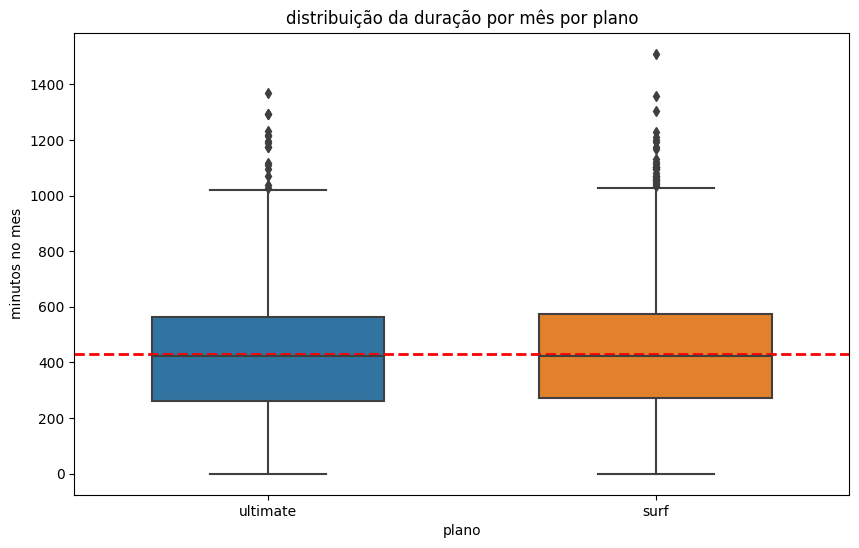

In [35]:
# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.boxplot(
    data = df_revenue,
    x = 'plan',
    y = 'total_minutes',
    width = 0.6
)

# Calcula a média dos minutos
mean_minutes = df_revenue['total_minutes'].mean()

# Adiciona linhas horizontais (não verticais) para um boxplot horizontal
plt.axhline(mean_minutes, color='red', linestyle='--', linewidth=2, label=f'Média: {mean_minutes:.2f}')

plt.title('distribuição da duração por mês por plano')
plt.xlabel('plano')
plt.ylabel('minutos no mes')
plt.show();


A boxplot mostra claramente a dispersao do uso de chamadas entre os planos, não mostra muita variabilidade  no tempo de chamada entre seus usuário, o plano surf apresenta maior presença de outliers o que pode representar que alguns usuários fazem chamadas muito acima do padrão, não há diferença entre as linhas de média o que significa que não há usuário com uso muito elevado que esteja distorcendo a média, especialmente para o plano surf.

[Formule conclusões sobre como os usuários se comportam em termos de chamadas. O comportamento é diferente dependendo do plano?]

### Mensagens

        plan  month  num_messages
0       surf      1     10.500000
1       surf      2     12.000000
2       surf      3     15.260870
3       surf      4     17.400000
4       surf      5     24.012987
5       surf      6     25.298969
6       surf      7     27.033058
7       surf      8     28.777778
8       surf      9     30.762887
9       surf     10     33.839662
10      surf     11     32.385159
11      surf     12     38.600629
12  ultimate      1     15.500000
13  ultimate      2     21.571429
14  ultimate      3     20.250000
15  ultimate      4     22.047619
16  ultimate      5     32.103448
17  ultimate      6     29.340426
18  ultimate      7     32.830508
19  ultimate      8     38.478873
20  ultimate      9     37.895349
21  ultimate     10     39.443396
22  ultimate     11     38.606299
23  ultimate     12     45.006623


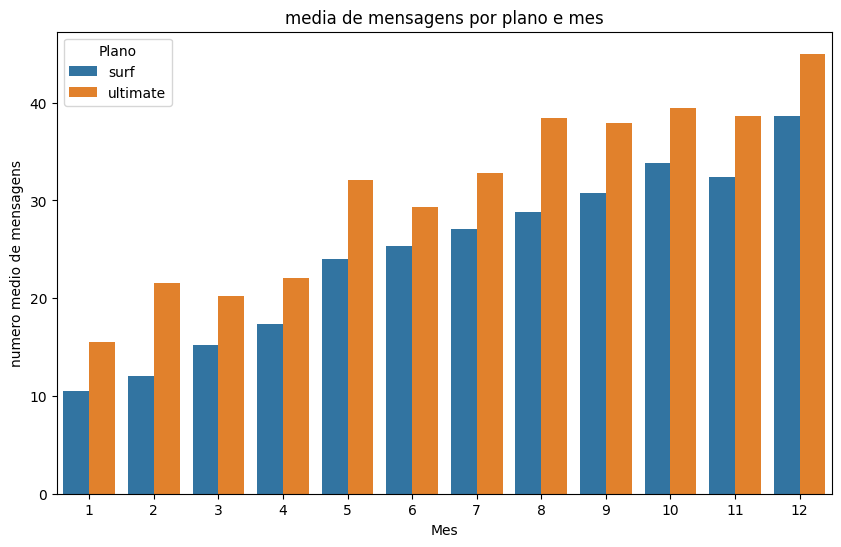

In [36]:
# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês

#escolhi a média aqui também para visualizar os dados conforme o comportamento do usuário naquele plano/mês e 
#comparar os perfis de uso

media_mensagens = (
    df_revenue.groupby(['plan', 'month'])['num_messages']
    .mean()
    .reset_index()
)
print(media_mensagens)

plt.figure(figsize=(10,6))
sns.barplot(
    data = media_mensagens,
    x = 'month',
    y = 'num_messages',
    hue = 'plan'
)
plt.title('media de mensagens por plano e mes')
plt.xlabel('Mes')
plt.ylabel('numero medio de mensagens'),
plt.legend(title = 'Plano')
plt.show()



Ambos os planos apresentam aumento crescente no número médio de mensagens enviadas, o plano ultimante está sempre com 5 a 9 mensagens a mais que o plano surf por mês, o plano ultimate parece atrair os usuários mais ativos por mensagens, pode ser que o pacote inclua maiores ou ilimitados sms e o surf apesar de um crescimento expressivo, mantem-se sempre em um patamar abaixo do ultimate, os usuários do surf podem ter um plano com menos sms e preferir usar outros canais de mensagens instantaneas ou ter um perfil de uso mais economico.

### Internet

       plan   total_gb
0      surf  16.170199
1  ultimate  16.811230


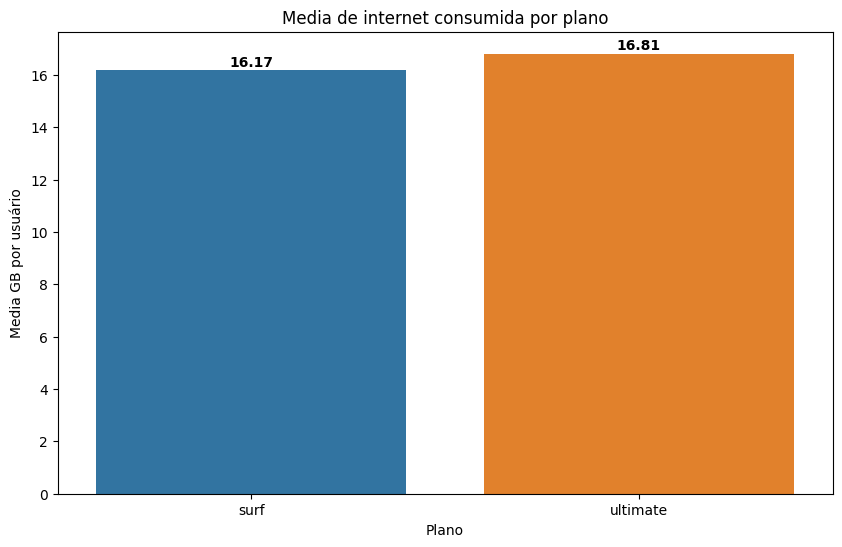

In [37]:
# Compare a quantidade de tráfego de internet consumido pelos usuários por plano
media_gb = (
    df_revenue.groupby(['plan'])['total_gb']
    .mean()
    .reset_index()
)
print(media_gb)

plt.figure(figsize=(10,6))
ax = sns.barplot(
    data = media_gb,
    x = 'plan',
    y = 'total_gb'
)

# Adiciona rótulos numéricos acima de cada barra
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():,.2f}',                       # valor da barra formatado com 2 casas decimais
        (p.get_x() + p.get_width()/2, p.get_height()),  # posição do rótulo: centro da barra, topo
        ha='center', fontweight='bold',                 # alinhamento central e negrito
        xytext=(0, 3), textcoords='offset points'       # desloca o texto 3 pontos acima da barra
    )
    
plt.title('Media de internet consumida por plano')
plt.xlabel('Plano')
plt.ylabel('Media GB por usuário'),
plt.show();

Os usuários do plano ultimate consomem significamente mais dados em média do que os usuários do plano surf.
    Isso indica que o plano Ultimate atrai um perfil de usuário com maior demanda por internet, possivelmente por uso intensivo de streaming, redes sociais, chamadas por vídeo ou trabalho remoto.

[Formule conclusões sobre como os usuários tendem a consumir o tráfego da internet. O comportamento é diferente dependendo do plano?]

## Receita

[Da mesma forma que você estudou o comportamento dos usuários, descreva estatisticamente as receitas dos planos.]

In [38]:
#estatísticas principais (contagem, média, desvio padrão, mínimo, quartis e máximo por plano)
estat_per_plan = df_revenue.groupby('plan')['monthly_revenue'].describe().T
print(estat_per_plan)

plan          surf    ultimate
count  1573.000000  720.000000
mean     60.706408   72.313889
std      55.388042   11.395108
min      20.000000   70.000000
25%      20.000000   70.000000
50%      40.360000   70.000000
75%      80.360000   70.000000
max     590.370000  182.000000


In [39]:
df_revenue['plan'].value_counts()

surf        1573
ultimate     720
Name: plan, dtype: int64

       plan  total_revenue
0      surf       95491.18
1  ultimate       52066.00
        plan  month      media      soma  mediana
0       surf      1  20.000000     40.00   20.000
1       surf      2  34.396667    309.57   29.570
2       surf      3  45.941304   1056.65   20.000
3       surf      4  40.710600   2035.53   20.000
4       surf      5  47.628182   3667.37   21.740
5       surf      6  49.276289   4779.80   30.150
6       surf      7  62.674050   7583.56   40.330
7       surf      8  63.931173  10356.85   41.980
8       surf      9  58.271495  11304.67   40.045
9       surf     10  65.421224  15504.83   50.000
10      surf     11  58.004276  16415.21   40.000
11      surf     12  70.557044  22437.14   50.000
12  ultimate      1  70.000000    280.00   70.000
13  ultimate      2  70.000000    490.00   70.000
14  ultimate      3  74.666667    896.00   70.000
15  ultimate      4  73.000000   1533.00   70.000
16  ultimate      5  70.724138   2051.00   70.000
17  ultimate      6

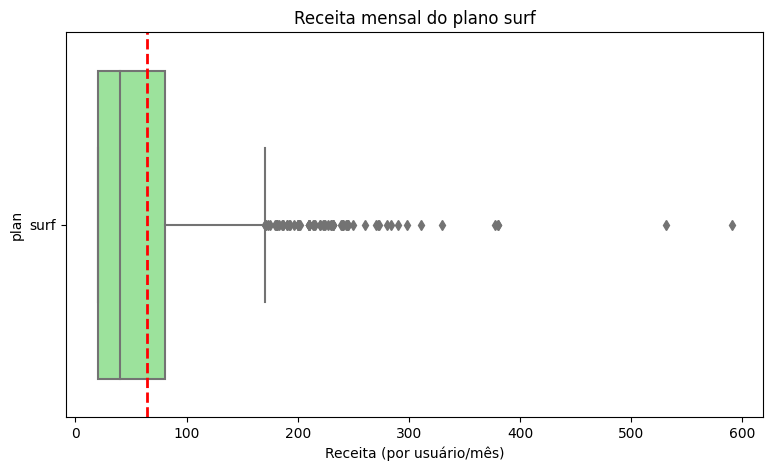

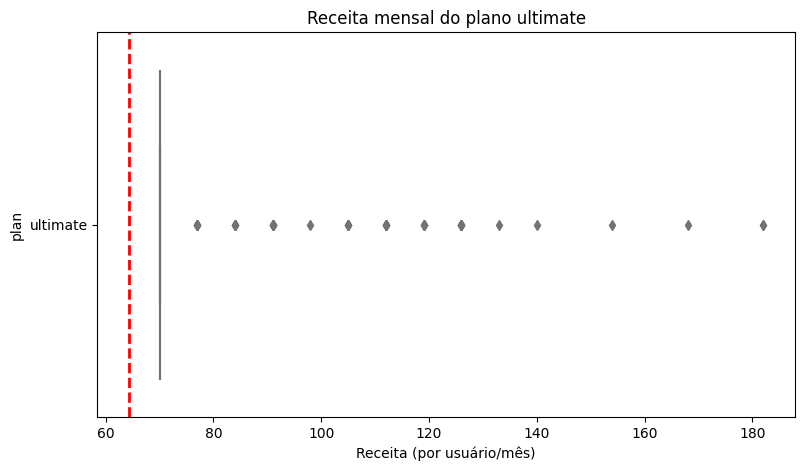

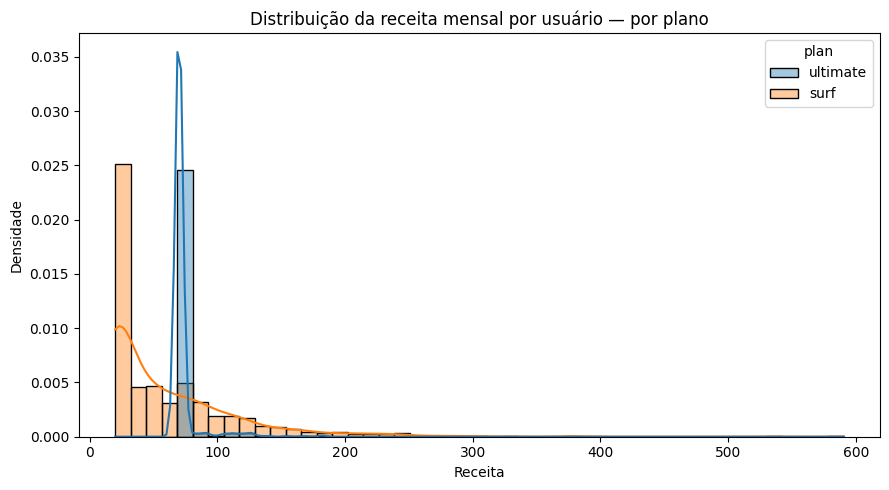

In [40]:
import math
#Receita total por plano
total_per_plan = (df_revenue
                .groupby('plan')['monthly_revenue']
                .sum()
                .reset_index(name = 'total_revenue')
                 )

print(total_per_plan)

#Receita média e total por plano e mês:
resume_month_plan = (df_revenue
                    .groupby(['plan', 'month'])['monthly_revenue']
                    .agg(media = 'mean', soma = 'sum', mediana = 'median')
                    .reset_index()
                    )

print(resume_month_plan.head(24))

#criação de boxplot por plano

import seaborn as sns
import matplotlib.pyplot as plt

# Gráficos como boxplots ajudam a identificar outliers e assimetrias.

plt.figure(figsize=(9,5))
sns.boxplot(data = df_revenue[df_revenue['plan'] == 'surf'], 
    x = 'monthly_revenue', 
    y = 'plan',
    color='lightgreen')

# Calcula a média da receita
mean_revenue = df_revenue['monthly_revenue'].mean()

# Adiciona uma linha vertical indicando a média
plt.axvline(mean_revenue, color='red', linestyle='--', linewidth=2, label=f'Média: {mean_revenue:.2f}')

plt.title('Receita mensal do plano surf')
plt.xlabel('Receita (por usuário/mês)')
plt.ylabel('plan')
plt.show();

plt.figure(figsize=(9,5))
sns.boxplot(data = df_revenue[df_revenue['plan'] == 'ultimate'], 
    x = 'monthly_revenue', 
    y = 'plan',
    color='lightgreen')

# Calcula a média da receita
mean_revenue = df_revenue['monthly_revenue'].mean()

# Adiciona uma linha vertical indicando a média
plt.axvline(mean_revenue, color='red', linestyle='--', linewidth=2, label=f'Média: {mean_revenue:.2f}')

plt.title('Receita mensal do plano ultimate')
plt.xlabel('Receita (por usuário/mês)')
plt.ylabel('plan')
plt.show();

# Histograma/KDE por plano
plt.figure(figsize=(9,5))
sns.histplot(data=df_revenue, x='monthly_revenue', hue='plan', bins=int(math.sqrt(df_revenue.shape[0])), multiple='layer', stat='density', alpha=0.4,kde = True)
#sns.kdeplot(data=df_revenue, x='monthly_revenue', hue='plan',color='lightgreen')
plt.title('Distribuição da receita mensal por usuário — por plano')
plt.xlabel('Receita')
plt.ylabel('Densidade')
plt.tight_layout() 
plt.show();

O plano Surf gerou uma receita total de 95.491.18, enquanto o plano Ultimate gerou 52.066,00.
Essa diferença reflete o maior número de usuários no plano Surf, embora o Ultimate apresente receita média por usuário mais elevada.
O crescimento da receita média e total no plano Surf ao longo dos meses sugere uma intensificação no uso dos serviços ou uma mudança no perfil de consumo dos usuários.
A estabilidade da mediana, contrastando com o aumento da média, indica a presença de outliers positivos, ou seja,usuários que geram receita muito acima da média e puxam os valores para cima.
A diferença entre os planos em termos de receita total está mais relacionada ao tamanho da base de clientes do plano Surf do que à receita individual.

[Formule conclusões sobre como a receita difere entre os planos.]

## Teste hipóteses estatísticas

[Teste a hipótese de que a receita média dos usuários dos planos Ultimate e Surf são diferentes.]

[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [41]:
# Teste as hipóteses
from scipy.stats import levene
from scipy.stats import ttest_ind  # Para teste t
from scipy.stats import mannwhitneyu  # Para teste Mann-Whitney

#Hipótese nula = receita média dos usuários dos planos Ultimate e Surf são iguais
#Hipóese alternativa = receita média dos usuários dos planos Ultimate e Surf são diferentes

# Seleciona a receita média do plano "Ultimate"
rev_ultimate = df_revenue[df_revenue['plan']=='ultimate']['monthly_revenue']

# Seleciona a receita média do plano "Surf"
rev_surf = df_revenue[df_revenue['plan']=='surf']['monthly_revenue']

# Teste de Levene para comparar as variâncias dos dois grupos
stat_levene, p_levene = levene(rev_ultimate,rev_surf)
print(f'Estatística de Levene: {stat_levene:.3f}, p-valor: {p_levene:.3f}')

# Decide se assume variâncias iguais ou não baseado no p-valor de Levene
if p_levene < 0.05:
    print("As variâncias são diferentes (usar equal_var=False no teste t).")
    equal_var = False
else:
    print("Não há evidências de variâncias diferentes (usar equal_var=True no teste t).")
    equal_var = True

# Somente para pular uma linha
print()

# Realiza o teste t para duas amostras independentes
# Compara se a média salarial dos Analistas é diferente da dos Cientistas
# equal_var=False utiliza a versão de Welch, que não assume variâncias iguais
t_stat, p_val = ttest_ind(rev_ultimate,rev_surf, equal_var=equal_var)

# Exibe o valor da estatística t e o p-valor do teste
print(f"Resultados do Teste:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.3f}")

# Exibe as médias salariais de cada grupo para comparação
print(f"Média Ultimate = {rev_ultimate.mean():.2f}, Média Surf = {rev_surf.mean():.2f}")


Estatística de Levene: 404.730, p-valor: 0.000
As variâncias são diferentes (usar equal_var=False no teste t).

Resultados do Teste:
t = 7.952, p-valor = 0.000
Média Ultimate = 72.31, Média Surf = 60.71


Rejeitamos a hipotése nula de que as receitas médias são iguais, há diferença estatisticamente significativa entre as médias dos planos, essa diferença entre as médias pode indicar que o plano ultimate atrai clientes com maior necessidade de gasto, seja pelos benefícios inclusos, poder aquisitivo ou perfil de uso.

<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

Correto. parabéns por usar teste Levene para avaliar variâncias </div>


[Teste a hipótese de que a receita média dos usuários da área de NY-NJ difere dos usuários das demais regiões.]

[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [42]:
# Teste as hipóteses

# Teste as hipóteses
from scipy.stats import levene, ttest_ind
import pandas as pd
from scipy.stats import mannwhitneyu  # Para teste Mann-Whitney

#Hipótese nula = receita média dos usuários da área de NY-NJ é igual a dos demais usuários.
#Hioótese alternativa = receita média dos usuarios da área de NY-NJ são diferentes a dos demais usuários.

#Adotamos α = 0.05 (5%), padrão para testes de hipótese.

#trazer a informação de city do df_users
df_merged_city = pd.merge(df_revenue, df_users[['user_id', 'city']], on='user_id', how = 'left')

#separar os grupos
ny_users = df_merged_city[df_merged_city['city'].str.contains('NY-NJ', na=False)]['monthly_revenue']
others_users = df_merged_city[~df_merged_city['city'].str.contains('NY-NJ', na=False)]['monthly_revenue']

# Teste de Levene para comparar as variâncias dos dois grupos
stat_levene, p_levene = levene(ny_users,others_users)
print(f'Estatística de Levene: {stat_levene:.3f}, p-valor: {p_levene:.3f}')

# Decide se assume variâncias iguais ou não baseado no p-valor de Levene
equal_var = p_levene > 0.05
if equal_var:
    print("Não há evidências de variâncias diferentes (usar equal_var=True no teste t).")
else:
    print("As variâncias são diferentes (usar equal_var=False no teste t).")

# Somente para pular uma linha
print()

# Realiza o teste t para duas amostras independentes
t_stat, p_val = ttest_ind(ny_users, others_users, equal_var=equal_var)
print(f"\nResultados do Teste:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.3f}")

# Exibe as médias salariais de cada grupo para comparação
print(f"Média NY-NJ = {ny_users.mean():.2f}, Média Outras = {others_users.mean():.2f}")


Estatística de Levene: 2.345, p-valor: 0.126
Não há evidências de variâncias diferentes (usar equal_var=True no teste t).


Resultados do Teste:
t = -2.019, p-valor = 0.044
Média NY-NJ = 59.92, Média Outras = 65.22


<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div> Ramon, tinha copy de códigos antigos e retirei e refiz o teste utilizando apenas a string NY-NJ, era isso?




<div class="alert alert-block alert-danger">
<b> Comentário do revisor v1: </b> <a class="tocSkip"></a>

- erro de execução. é importante limpar e executar noteobok antes de enviar para garantir ausência de erro
- oriento testard ['city'].str.contains('NY-NJ')
</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor v2: </b> <a class="tocSkip"></a>

Correto. Agora o código está mais limpo, sem erros e pythonic

</div>


Rejeitamos a hipotese nula de que as receitas médias são iguais, há diferença estatisticamente significativa entre as médias dos dois grupos.
Essa diferença entre as média das regiões pode ser explicada por fatores como perfil de uso, promoções regionais ou do plano contratado.

## Conclusão geral

[Liste suas conclusões importantes nesta seção final, certifique-se de que elas cobrem todas as decisões (suposições) importantes que você tomou e que levaram à maneira como você processou e analisou os dados.]

A análise revelou que, embora existam diferenças aparentes entre planos e regiões, estas não se mostraram estatisticamente significativas dentro do nível de confiança adotado,porém a variabilidade observada e o perfil de uso dos clientes sugerem que decisões comerciais devem considerar não apenas médias, mas também dispersão, comportamento por segmento e potencial de receita individual.